**PROYECTO: Modelado espacial para estimar la susceptibilidad a inundaciones usando algoritmos de aprendizaje automatico con datos geomorfologicos**

Autor: Sebastian Velosa Bohorquez. Curso: Percepción Remota Avanzada.

**NOTEBOOK 05/07**

# Inventario de Inundaciones

**Objetivo:** Este notebook genera un archivo `.tiff ` con informacion de zonas inundadas/no inundadas para la zona estudio de la Cuenca del Bajo Sinu.

***Contenido:***
1. Instalar librerías
2. Conectar con Google Drive y Code Earth Engine
3. Definir rutas de los archivos
4. Cargar el AOI y el inventario desde GEE
5. Importar datos CRS del DEM referencia
6. Alineación datos de inundación.
7. Aplicar la máscara del DEM
8. Guardar GeoTIFF Alineado
9. Comprobar Alineación
10. Estadísticas y visualización
11. Verificar archivo y descargar resultados

### *Antes de ejecutar*

**Datos:** COPERNICUS GLO 30 DEM previamente alineado en formato `.tiff` . Raster con areas de inundacion `"FloodInventory_v1"`

#1. Instalar e importar librerías

In [ ]:
%pip install -q earthengine-api geemap

In [ ]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import rasterio
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


from google.colab import files
from google.colab import drive
from rasterio.mask import mask
from rasterio.warp import transform_geom
from shapely.geometry import shape

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


#2. Conectar Google Drive y Earth Engine

In [ ]:
ee.Authenticate()

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Identificador de Google Cloud
PROJECT_ID = "sinu-flood-susceptibility"


# Inicializar Earth Engine
ee.Initialize(project=PROJECT_ID)

print("Conexión con Earth Engine establecida")
print("Proyecto:", PROJECT_ID)
print(ee.String("Earth Engine está operativo").getInfo())

Conexión con Earth Engine establecida
Proyecto: sinu-flood-susceptibility
Earth Engine está operativo


#3. Definir rutas de archivos

En este paso cargamos desde GEE el asset con la informacion binaria de pixeles con clase inundado [1], no inundado [0].
Asi mismo, cargamos el DEM alineado en el notebook 03 que usaremos como referencia de grilla.



In [ ]:
ASSET_FLOOD = (
    'projects/sinu-flood-susceptibility/assets/02_SAR/FloodInventory_v1'
)

RUTA_DEM = '/content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/Copernicus_GLO30_Sinu_alineado.tif'
RUTA_TEMP = '/content/FloodInventory_temporal.tif'
RUTA_SALIDA = '/content/drive/MyDrive/GEE/FloodInventory_alineado.tif'

NODATA = 255

#4. Cargar el AOI y el inventario desde GEE

Cargamos el asset con el area de estudio

In [ ]:

aoi_ee = ee.FeatureCollection(
    'users/savelosab_practiques/Cuenca_Baja_RioSinu'
)

flood = ee.Image(ASSET_FLOOD).select('b1')

Descargar el inventario a una resolución de 30 m.

In [ ]:

# La alineación exacta se hará después utilizando el DEM.
geemap.ee_export_image(
    flood.unmask(NODATA).toByte(),
    filename=RUTA_TEMP,
    scale=30,
    crs='EPSG:31972',
    region=aoi_ee.geometry(),
    file_per_band=False
)

Generating URL ...
Please wait ...
Data downloaded to /content/FloodInventory_temporal.tif


#5.Importar datos CRS del DEM referencia

La cuadricula del DEM ya fue alineada en el notebook 03, asi que tomamos sus datos para la alineacion del inventario.

In [ ]:
# 4. Tomar la cuadrícula del DEM como referencia
with rasterio.open(RUTA_DEM) as dem:

    perfil = dem.profile.copy()

    transform_grid = dem.transform
    crs_grid = dem.crs
    ancho = dem.width
    alto = dem.height

    # Máscara de píxeles válidos del DEM
    mascara_dem = dem.read_masks(1) > 0

    destino = np.full(
        (alto, ancho),
        NODATA,
        dtype=np.uint8
    )


#6. Alinear los datos de inundacion a la cuadricula DEM

In [ ]:
# Alinear el inventario a la cuadrícula del DEM
with rasterio.open(RUTA_TEMP) as src:

    origen = src.read(1)

    # Verificar las clases presentes en el inventario
    clases = np.unique(origen)
    print('Valores del inventario original:', clases)

    reproject(
        source=origen,
        destination=destino,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=NODATA,
        dst_transform=transform_grid,
        dst_crs=crs_grid,
        dst_nodata=NODATA,
        resampling=Resampling.nearest
    )


Valores del inventario original: [0 1]


#7. Aplicar la máscara del DEM

In [ ]:
# Aplicar la máscara del DEM
destino[~mascara_dem] = NODATA

# Verificar que no existan clases diferentes de 0 y 1
clases_finales = np.unique(destino)
print('Clases finales:', clases_finales)

assert set(clases_finales).issubset({0, 1, NODATA})

Clases finales: [  0   1 255]


#8. Guardar GeoTIFF Alineado

In [ ]:
# Guardar GeoTIFF alineado

perfil_salida = {
    'driver': 'GTiff',
    'height': alto,
    'width': ancho,
    'count': 1,
    'dtype': 'uint8',
    'crs': crs_grid,
    'transform': transform_grid,
    'nodata': NODATA,
    'compress': 'lzw',
    'tiled': True
}

with rasterio.open(RUTA_SALIDA, 'w', **perfil_salida) as dst:
    dst.write(destino, 1)

print('Archivo guardado correctamente:')
print(RUTA_SALIDA)

Archivo guardado correctamente:
/content/drive/MyDrive/GEE/FloodInventory_alineado.tif


# 9. Comprobar Alineación

In [ ]:

with rasterio.open(RUTA_SALIDA) as resultado:

    print('CRS:', resultado.crs)
    print('Resolución:', resultado.res)
    print('Dimensiones:', resultado.width, resultado.height)
    print('Transformación:', resultado.transform)

    assert resultado.crs == crs_grid
    assert resultado.width == ancho
    assert resultado.height == alto
    assert resultado.transform == transform_grid

CRS: EPSG:31972
Resolución: (30.0, 30.0)
Dimensiones: 3103 3848
Transformación: | 30.00, 0.00, 364080.00|
| 0.00,-30.00, 1044510.00|
| 0.00, 0.00, 1.00|


# 10. Estadísticas y visualización


Frecuencia de clases:
No inundado: 6,035,219 píxeles
Inundado: 484,494 píxeles


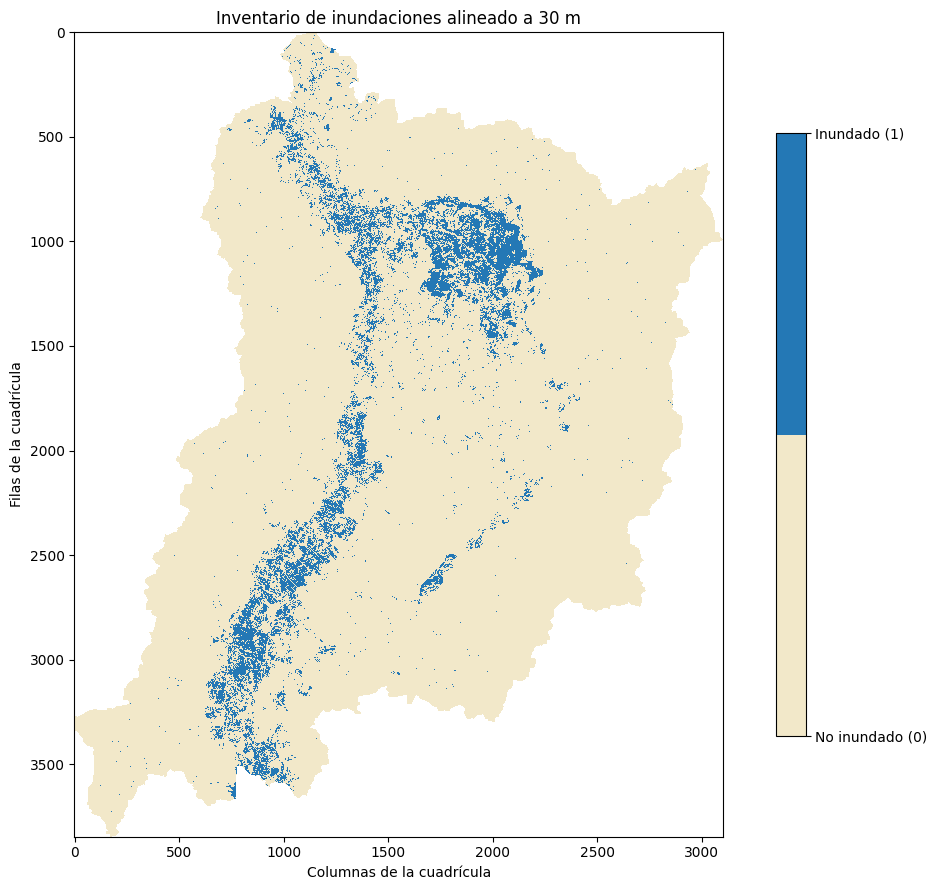

In [ ]:

validos = destino != NODATA
valores, frecuencias = np.unique(
    destino[validos],
    return_counts=True
)

print('\nFrecuencia de clases:')
for valor, frecuencia in zip(valores, frecuencias):
    nombre = 'No inundado' if valor == 0 else 'Inundado'
    print(f'{nombre}: {frecuencia:,} píxeles')

plt.figure(figsize=(11, 9))

plt.imshow(
    np.ma.masked_equal(destino, NODATA),
    cmap=plt.matplotlib.colors.ListedColormap(
        ['#f2e8c9', '#2478b5']
    ),
    vmin=0,
    vmax=1,
    interpolation='none'
)

plt.title('Inventario de inundaciones alineado a 30 m')
plt.xlabel('Columnas de la cuadrícula')
plt.ylabel('Filas de la cuadrícula')

cbar = plt.colorbar(ticks=[0, 1], shrink=0.75)
cbar.ax.set_yticklabels(['No inundado (0)', 'Inundado (1)'])

plt.tight_layout()
plt.show()

# 11. Verificar archivo y descargar

In [ ]:



if os.path.exists(RUTA_SALIDA):

    print('Archivo encontrado.')
    print('Tamaño:', round(os.path.getsize(RUTA_SALIDA) / 1024**2, 2), 'MB')

    with rasterio.open(RUTA_SALIDA) as src:
        print('CRS:', src.crs)
        print('Resolución:', src.res)
        print('Dimensiones:', src.width, src.height)
        print('NoData:', src.nodata)
        print('Transformación:', src.transform)

    files.download(RUTA_SALIDA)

else:
    print('No se encontró el archivo. Revisa la ruta de salida.')

Archivo encontrado.
Tamaño: 0.25 MB
CRS: EPSG:31972
Resolución: (30.0, 30.0)
Dimensiones: 3103 3848
NoData: 255.0
Transformación: | 30.00, 0.00, 364080.00|
| 0.00,-30.00, 1044510.00|
| 0.00, 0.00, 1.00|


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>